# **Predição de óbito ou readmissão em 6 meses em pacientes com insuficiência cardíaca**

Trabalho final de Inteligência Computacional Aplicada a Problemas de Engenharia (UFMG 2026/2).

**Objetivo**: a partir das informações disponíveis na internação, prever se o paciente terá **óbito ou readmissão hospitalar em até 6 meses** (classificação binária).

Este *notebook* funciona como o **painel executivo** do projeto. Toda a lógica de processamento de dados e engenharia de atributos foi modularizada para os ficheiros Python `.py` na pasta `src/`.

Etapas:
1. Carregamento dos Dados
2. Análise exploratória dos dados (EDA)
3. Extração e seleção de atributos
4. Treinamento de modelos lineares e não lineares
5. Avaliação e seleção de modelos

## Sobre a base de dados

**Hospitalized patients with heart failure: integrating electronic healthcare records and external outcome data**, versão 1.3 (22/05/2022), PhysioNet.

- **Origem**: prontuários eletrônicos do *Zigong Fourth People's Hospital* (Sichuan, China), internações entre **dezembro/2016 e junho/2019**.
- **População**: **2008 pacientes** internados consecutivamente com insuficiência cardíaca (IC), diagnosticada pelos critérios da *European Society of Cardiology*.
- **Conteúdo** (`dat.csv`): dados demográficos e de admissão, sinais vitais, classificação da IC (tipo, NYHA, Killip), comorbidades (índice de Charlson), nível de consciência (Glasgow), ecocardiograma, ~100 exames laboratoriais e **desfechos de seguimento**.
- **Medicamentos** (`dat_md.csv`): fármacos administrados durante a internação (diuréticos, inotrópicos, vasodilatadores, etc.), em formato longo.

**Referência:** Zhang, Z., Cao, L., Zhao, Y., Xu, Z., Chen, R., Lv, L., & Xu, P. (2022). *Hospitalized patients with heart failure: integrating electronic healthcare records and external outcome data* (version 1.3). PhysioNet. https://doi.org/10.13026/5m60-vs44

## **Fase 1: Análise Exploratória de Dados (EDA) e Pré-Requisitos**

## Configurações Iniciais

Utilizamos o módulo `src/utils.py` para padronizar diretórios, variáveis globais e temas de plotagem (Matplotlib/Seaborn). 

In [27]:
# Pedir ao IPython para recarregar módulos automaticamente
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Adiciona a raiz do repositório ao sys.path
BASE_DIR = Path.cwd().resolve().parent
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))

# Importações dos módulos customizados
from src import utils, preprocessing, features, eda

# Aplica o tema visual padronizado para gráficos
utils.setup_plotting()

## Carregamento dos Dados

Os dados brutos são carregados através da função `load_data()` do módulo `preprocessing.py`. Ela obtém os dados clínicos (`dat.csv`), a tabela de medicamentos (`dat_md.csv`) e o dicionário de variáveis.

In [29]:
patients, drugs, data_dictionary = preprocessing.load_data()

print(f"Base clínica (pacientes x variáveis): {patients.shape}")
print(f"Base de medicamentos (pacientes x medicamento): {drugs.shape}")
print(f"Dicionário das variáveis (variáveis x descrição): {data_dictionary.shape}")

Base clínica (pacientes x variáveis): (2008, 166)
Base de medicamentos (pacientes x medicamento): (15362, 2)
Dicionário das variáveis (variáveis x descrição): (166, 2)


### 1.1. Dicionário de Variáveis

As 166 colunas clínicas foram agrupadas em 18 domínios médicos (ex: Demografia, Comorbidades, Sinais Vitais, Lab - Gasometria) utilizando o arquivo de metadados. Isso facilita a remoção em bloco de variáveis de vazamento (data leakage). Os grupos *Identificação*, *Desfechos e seguimento* e *Informações da alta* só são conhecidos após a alta (ou não são informação clínica) e serão removidos posteriormente.

In [30]:
variable_groups = preprocessing.get_variable_groups(patients)
print(f"Foram definidos {len(variable_groups)} grupos de variáveis.")

Foram definidos 18 grupos de variáveis.


#### 1.1.1. Resumo Visual do Dicionário

Através do módulo `eda.py`, conseguimos gerar a tabela que mapeia todos os campos, a quantidade de dados em falta e os valores observados para cada variável clínica.

- **Dados brutos:** A função `generate_variable_overview` gera um arquivo CSV com os dados brutos, salvando na pasta `results/csv`. 
- **Tabelas detalhadas por grupo clínico:** As 18 tabelas detalhadas (variável, descrição, tipo, % de faltantes e valores observados) não são exibidas aqui. A função `export_variable_overview_pdf` exporta as tabelas para um arquivo PDF, com uma tabela por grupo, uma por página, salvando na pasta `results`. 

In [31]:
overview = eda.generate_variable_overview(patients, data_dictionary, variable_groups)
eda.export_variable_overview_pdf(overview)

Resumo por Grupo Clínico:


,n_variáveis,faltantes_médio,faltantes_máx
grupo,,,
Identificação,1,0.0,0.0
Demografia,3,0.4,1.3
Admissão e histórico,3,0.0,0.0
Sinais vitais e antropometria,9,0.0,0.0
Classificação da IC,3,0.0,0.0
Comorbidades,17,0.0,0.2
Estado clínico na admissão,10,9.8,97.9
Ecocardiograma,7,65.6,90.9
Lab. — função renal,5,1.7,3.1


/home/luishcr/iic_projeto_final/heart-failure-outcome-prediction-fork1/results/csv/variable_overview.csv

/home/luishcr/iic_projeto_final/heart-failure-outcome-prediction-fork1/results/variable_overview.pdf

### 1.2 Medicamentos (`dat_md.csv`)

A base de medicamentos encontra-se num **formato longo** (uma linha por par paciente-fármaco). Nesta versão, a informação disponível é apenas binária: **usou ou não usou** determinado fármaco, sem dosagem nem frequência.

In [32]:
drug_summary = eda.generate_drug_summary(drugs, patients)
display(drug_summary.head()) # Mostra apenas o top 5

Internações com ao menos um medicamento: 2007 de 2008
Internações presentes em drugs e ausentes de patients: 0


,registros,internações,internações (%)
Drug_name,,,
Spironolactone tablet,1833,1833,91.3
Furosemide injection,1718,1718,85.6
Furosemide tablet,1641,1641,81.7
Meglumine Adenosine Cyclophosphate for injection,1114,1114,55.5
Deslanoside injection,1015,1015,50.5


### 1.3 Valores Faltantes e Padrão NMAR

Exames como gasometria (50% de ausência) faltam em bloco não por erro, mas por não solicitação médica (Not Missing At Random). Tentar imputar esses dados geraria um viés artificial severo.\
**Decisão Metodológica**: Ausências acima de 20% não serão imputadas. Serão convertidas em colunas indicadoras binárias (Missing Flags) na extração de atributos, capturando o julgamento clínico.

> Filtragem: Para não poluir o gráfico, a função exclui as variáveis que estão 100% preenchidas e ordena as restantes da menor para a maior taxa de ausência.

Nº de variáveis por faixa de faltantes:
0%            50
(0, 20]%      68
(20, 50]%      4
(50, 100]%    44

respiratory.support. — faltantes: 97.9%
Internações sem nenhum faltante: 0


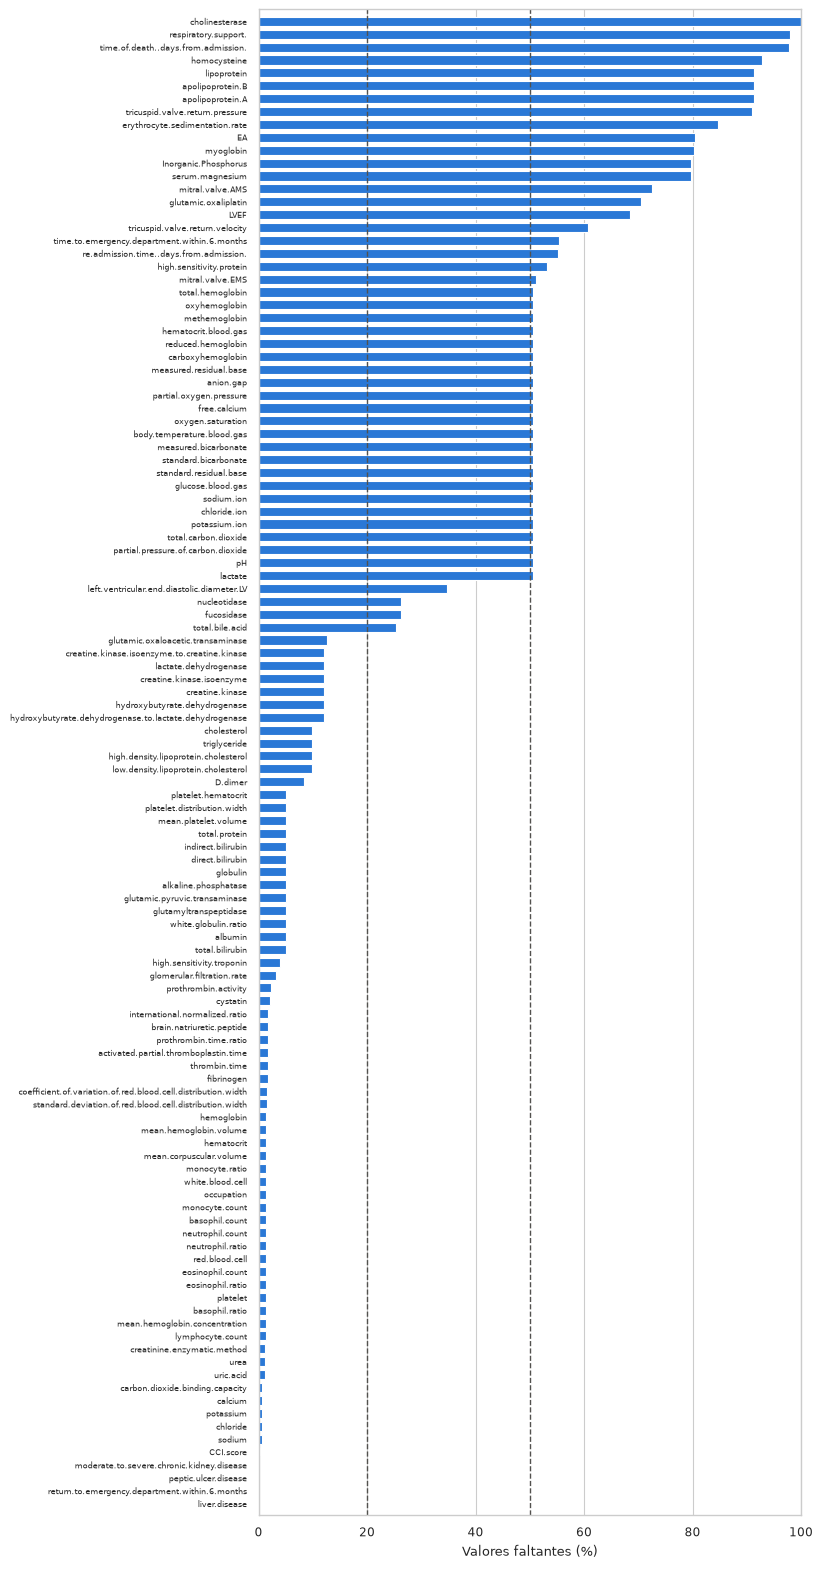

/home/luishcr/iic_projeto_final/heart-failure-outcome-prediction-fork1/results/figures/missing_rate_by_variable.pdf

In [33]:
eda.plot_missing_rate_by_variable(patients)

**Quanto falta em cada variável**: 
- Cada barra é uma variável com algum faltante. As linhas tracejadas marcam 20% e 50%, limiares usuais na literatura para descartar uma variável em vez de imputá-la. Serve para escolher esse limiar posteriormente: há um grupo grande acima de 50% (gasometria, lipídios, ecocardiograma) e quase todo o resto abaixo de 20%.

**Interpretação para a modelagem**:
- Abaixo de 20%: Valores ausentes aqui (como em alguns exames básicos) costumam ser aleatórios e seguros para imputação (substituir o nulo pela mediana ou média da população).
- Acima de 50%: Barras longas que ultrapassam a segunda linha (como gasometria, lipoproteínas, ou respiratory.support. com 97,9% de ausência) indicam dados que não faltam ao acaso (Not Missing At Random). Tentar "adivinhar" o valor para 70% dos pacientes introduziria um viés grave. Em vez disso, a imagem justifica a adoção de Missing Flags (criar uma coluna binária dizendo "o exame não foi pedido"), pois a ausência carrega a informação clínica de que o médico não suspeitou daquela complicação.

#### 1.3.1 Matriz de Valores Faltantes

Esta visualização comprova o padrão NMAR (Not Missing At Random). As faixas que atravessam o painel confirmam que não faltam pontos aleatórios de dados, mas sim painéis inteiros que não foram solicitados pelo médico.\
A função `plot_missing_matrix` gera um "mapa de calor" booleano que permite visualizar a estrutura e o comportamento dos dados ausentes em toda a base de pacientes.
O eixo horizontal representa as variáveis agrupadas, e o eixo vertical representa os 2.008 pacientes. Onde o dado está preenchido, a imagem fica na cor clara (fundo neutro); onde o dado é nulo/ausente, a imagem é preenchida por blocos azuis (cor da série).
- **Impacto na Modelagem**: Esse comportamento em bloco demonstra que a ausência ocorre porque o painel laboratorial inteiro não foi solicitado pelo médico. Como essa ausência indica uma decisão médica presuntiva (o médico julgou o paciente estável o suficiente para não precisar da gasometria, por exemplo), a imagem suporta metodologicamente a decisão de não imputar esses valores, mas sim transformá-los em atributos indicativos (Missing Flags).

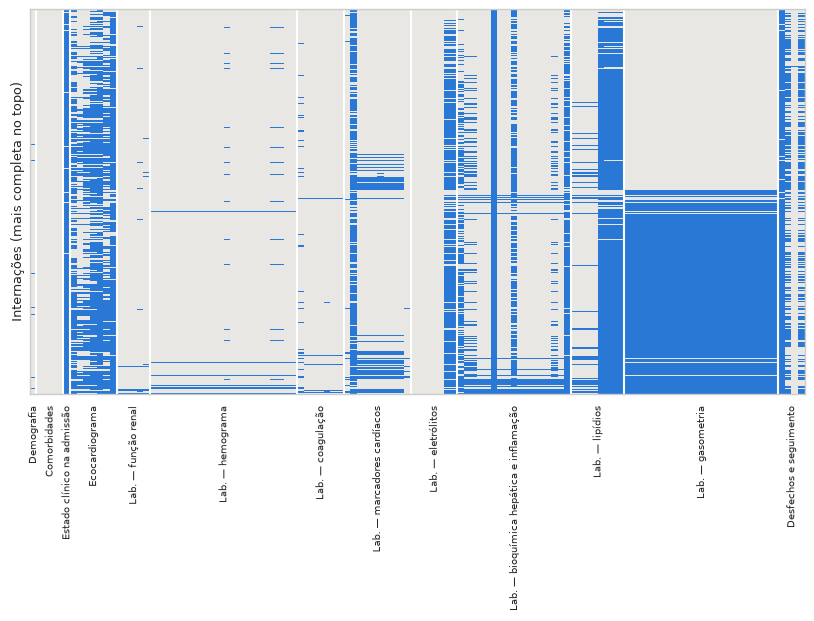

/home/luishcr/iic_projeto_final/heart-failure-outcome-prediction-fork1/results/figures/missing_matrix.pdf

In [34]:
eda.plot_missing_matrix(patients, variable_groups)

### 1.4 Variável Alvo: Óbito ou Readmissão em 6 meses

Variável resposta (binária) estabelecida combinando o óbito (qualquer momento em até 6 meses) e a readmissão hospitalar. O desfecho composto evita o viés de risco competitivo e confere um balanceamento adequado de classes para o treinamento.

**Definição**: `target = 1` se o paciente foi readmitido em qualquer janela registrada (28 dias, 3 ou 6 meses) **ou** morreu em até 6 meses; senão `target = 0`. Usar qualquer janela de readmissão (e não só a de 6 meses) cobre 3 registros inconsistentes em que há readmissão em 3 meses mas não em 6 (ver checagem abaixo).

**Composição do alvo e checagens de consistência**: Os desfechos são cumulativos no tempo (quem teve o evento em 28 dias deve tê-lo também em 3 e 6 meses); óbito e readmissão em 6 meses não se sobrepõem nesta base. Os óbitos durante a própria internação também entram no alvo, pois estão contidos em `death.within.6.months`.

Total no alvo: 833 de 2008 (41.5%)


,positivos,prevalência (%)
Óbito em 28 dias,37,1.8
Óbito em 3 meses,42,2.1
Óbito em 6 meses,57,2.8
Readmissão em 28 dias,140,7.0
Readmissão em 3 meses,498,24.8
Readmissão em 6 meses,773,38.5
Retorno ao PS em 6 meses,775,38.6
Óbito ou readmissão em 6 meses (alvo),833,41.5


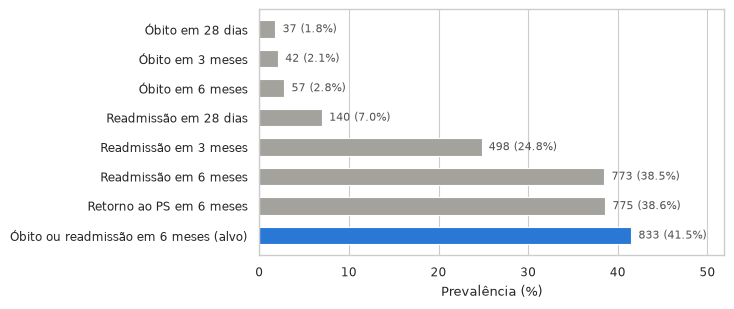

/home/luishcr/iic_projeto_final/heart-failure-outcome-prediction-fork1/results/figures/outcome_prevalence.pdf

In [35]:
target = preprocessing.create_target(patients)
print(f"Total no alvo: {target.sum()} de {len(target)} ({target.mean():.1%})")

# Gera a tabela de resumo, o gráfico de barras (prevalência) e o detalhamento
eda.plot_outcome_prevalence(patients, target)
# eda.print_outcome_details(patients, target)

### 1.5 Análise Bivariada Clínica 

A tabela e os boxplots abaixo descrevem as características basais da internação estratificadas pelo desfecho (Estável vs. Óbito/Readmissão).
Objetivo: Verificar a coerência clínica preliminar (ex: maior gravidade nas escalas NYHA e Killip para pacientes com evento) e identificar a distribuição (presença de outliers biológicos severos, como no peptídeo natriurético BNP), justificando a necessidade futura de imputação baseada na mediana e padronização das escalas.

Característica,Estável (0),Óbito/Readmissão (1)
[ Contínuas: Média ± DP ],,
BMI,21.88 ± 13.54,21.66 ± 13.81
LVEF,50.79 ± 13.49,50.54 ± 12.86
CCI.score,1.79 ± 0.89,1.96 ± 1.05
systolic.blood.pressure,132.93 ± 24.42,128.42 ± 24.97
[ Categóricas: Distribuição % ],,
"ageCat = (21,29]",0.1%,0.4%
"ageCat = (29,39]",0.9%,0.1%
"ageCat = (39,49]",3.1%,2.3%
"ageCat = (49,59]",5.3%,5.3%


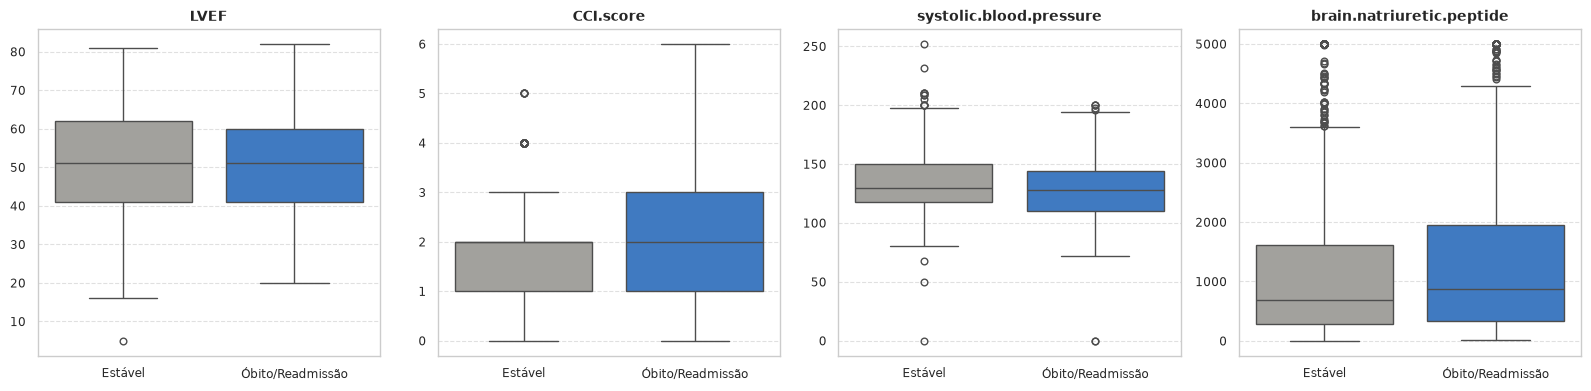

/home/luishcr/iic_projeto_final/heart-failure-outcome-prediction-fork1/results/figures/bivariate_clinical_analysis.pdf

In [36]:
# Seleção de características centrais para compor a tabela base do artigo
key_clinical_features = [
    'ageCat', 'gender', 'BMI', 'LVEF', 'CCI.score', 
    'systolic.blood.pressure', 'Killip.grade', 'NYHA.cardiac.function.classification'
]

# Gera a estratificada
eda.generate_table1_stratified(patients, target, key_clinical_features)

# Plota os gráficos comparativos para identificação visual de outliers e separabilidade
eda.plot_clinical_bivariate(patients, target)

### 1.6 Análise de Correlação e Colinearidade

Identifica variáveis com alta dependência linear que podem prejudicar modelos paramétricos

In [37]:
# Identifica pares preditores com forte dependência linear (Pearson > 0.85)
collinear_df = eda.analyze_collinearity(patients, threshold=0.85)

--- Pares Altamente Correlacionados (Pearson > 0.85) ---


Variável 1,Variável 2,Correlação (Pearson)
EA,tricuspid.valve.return.pressure,1.000
re.admission.time..days.from.admission.,time.to.emergency.department.within.6.months,1.000
total.carbon.dioxide,measured.bicarbonate,0.999
reduced.hemoglobin,oxygen.saturation,0.999
international.normalized.ratio,prothrombin.time.ratio,0.997
standard.bicarbonate,measured.residual.base,0.996
reduced.hemoglobin,oxyhemoglobin,0.995
oxygen.saturation,oxyhemoglobin,0.995
standard.residual.base,measured.residual.base,0.993
standard.residual.base,standard.bicarbonate,0.991


## **Fase 2: Extração, Seleção e Redução de Atributos**

Fase crítica para selecionar as variáeis preditoras e criar modelos interpretáveis.

### 2.1. Vazamento de Informação (Data Leakage) e Dados Ausentes (Missing Flags)

A função `features.build_feature_set()` executa três passos críticos de forma limpa e modular:
1. **Remoção de Vazamento de Informação (Data Leakage)**: Remove desfechos temporais e informações exclusivas do momento da alta.
2. **Missing Flags**: Cria colunas indicadoras binárias (ex: `coluna_is_missing = 1`) para exames com mais de 20% de valores nulos.
3. **Pivotamento de Medicamentos**: Transforma a base `dat_md.csv` para o formato *wide*, em que cada fármaco se torna uma coluna binária acoplada à base clínica.

In [38]:
# 1. Remoção de Vazamento de Informação (Data Leakage)
X = features.build_feature_set(patients, drugs, variable_groups)

print(f"\nDimensão original: {patients.shape}")
print(f"Dimensão da matriz preditora após remover vazamento: {X.shape}")

# 2. Tipologia explícita
variable_types = preprocessing.get_variable_types(X)
print("\nDistribuição da tipologia das variáveis preditoras:")
print(f"- Contínuas: {len(variable_types['continuas'])}")
print(f"- Discretas: {len(variable_types['discretas'])}")
print(f"- Binárias: {len(variable_types['binarias'])}")
print(f"- Categóricas: {len(variable_types['categoricas'])}")

Base de medicamentos processada: 25 fármacos extraídos.
Removidas 14 colunas de vazamento. Restam 176 atributos clínicos.
Adicionados 45 indicadores de dados em falta (threshold > 20.0%).
Removidas 4 colunas vazias/constantes: ['leukemia', 'cholinesterase', 'body.temperature.blood.gas', 'cholinesterase_is_missing']

Dimensão original: (2008, 166)
Dimensão da matriz preditora após remover vazamento: (2008, 217)

Distribuição da tipologia das variáveis preditoras:
- Contínuas: 113
- Discretas: 7
- Binárias: 85
- Categóricas: 12


### 2.2 Pré-processamento Matemático e Seleção de Atributos

Com a matriz preditora $X$ ($2008 \times 221$) no regime clássico ($n > p$), o principal desafio estatístico é a multicolinearidade severa identificada na Fase 1, e não a alta dimensionalidade estrita. O pré-processamento é encapsulado em um `ColumnTransformer` com três fluxos distintos:

* **Contínuas e Discretas (120):** Imputação pela mediana (robusta aos *outliers* laboratoriais) seguida de padronização (`StandardScaler`).
* **Categóricas (7):** Imputação pela moda seguida de `OneHotEncoder(drop="first")`.
* **Binárias (94):** Imputação pela moda apenas para proteção contra nulos residuais ($\le 0,2\%$), preservando a escala $\{0, 1\}$.

Para modelos sem regularização nativa (LDA, QDA, KNN e SVM), definimos um seletor embutido baseado em regularização L1 (LASSO) para zerar coeficientes redundantes e preservar a interpretabilidade clínica. Ambas as estruturas são apenas instanciadas nesta etapa e serão ajustadas (`.fit()`) exclusivamente dentro dos *folds* de validação cruzada na Fase 3, impedindo vazamento de dados (*data leakage*).

In [39]:
# Instanciação do pré-processador e do seletor L1 (sem ajuste prévio aos dados)
preprocessor = features.build_preprocessor(variable_types)

print("Pré-processador configurado:")
display(preprocessor)


Pré-processador configurado:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

## **Fase 3: Treinamento de Modelos**

In [40]:
from src import utils, preprocessing, features, eda, train

### 3.1 Particionamento e Validação Cruzada Estratificada

Os dados são divididos de forma estratificada em **Treino (80%, $n=1.606$)** e **Teste (20%, $n=402$)**, mantendo o conjunto de teste isolado para a avaliação imparcial final.

Para comparar de forma justa as abordagens lineares regularizadas e não lineares baseadas em árvores, treinamos quatro modelos candidatos encapsulados diretamente no `ColumnTransformer` (garantindo que imputação e padronização ocorram exclusivamente dentro de cada dobra da validação cruzada):
1. **Regressão Logística (LASSO $\ell_1$):** Baseline linear esparso com seleção intrínseca de variáveis.
2. **Regressão Logística (Ridge $\ell_2$):** Baseline linear denso com encolhimento contínuo de coeficientes.
3. **Random Forest (*Bagging*):** Comitê de árvores descorrelacionadas para redução de variância.
4. **Gradient Boosting:** Comitê sequencial de árvores rasas para redução de viés.

In [41]:
# 1. Divisão estratificada (80% treino / 20% teste)
X_train, X_test, y_train, y_test = train.split_data(X, target, test_size=0.2, random_state=42)
print(f"Conjunto de Treino: {X_train.shape} | Prevalência do alvo: {y_train.mean():.1%}")
print(f"Conjunto de Teste:  {X_test.shape} | Prevalência do alvo: {y_test.mean():.1%}")

# 2. Treinamento e ajuste de hiperparâmetros via Validação Cruzada Estratificada (5-Fold)
best_models, cv_summary = train.train_and_validate(
    X_train, y_train, preprocessor, cv_splits=5, random_state=42
)

print("\n--- Resultados da Validação Cruzada (Conjunto de Treino) ---")
display(
    cv_summary.style.hide(axis="index").format({
        "ROC-AUC (CV Média)": "{:.4f}",
        "ROC-AUC (CV DP)": "{:.4f}",
    })
)

Conjunto de Treino: (1606, 217) | Prevalência do alvo: 41.5%
Conjunto de Teste:  (402, 217) | Prevalência do alvo: 41.5%

--- Resultados da Validação Cruzada (Conjunto de Treino) ---


Modelo,ROC-AUC (CV Média),ROC-AUC (CV DP),Melhores Hiperparâmetros
Random Forest (Bagging),0.6646,0.0360,"{'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 400}"
Gradient Boosting,0.6553,0.0262,"{'learning_rate': 0.1, 'max_depth': 5, 'min_samples_leaf': 40}"
Regressão Logística (LASSO L1),0.6476,0.0294,{'C': 0.1}
Regressão Logística (Ridge L2),0.6362,0.0348,{'C': 0.01}


## **Fase 4: Avaliação e Seleção de Modelos**

In [42]:
from src import utils, preprocessing, features, eda, train, evaluate

### 4.1 Avaliação Final no Conjunto de Teste

Avaliamos os quatro modelos ajustados sobre o conjunto de teste isolado ($n=402$), comparando métricas de classificação, curvas ROC/AUC e a matriz de confusão do modelo de melhor desempenho.

--- Desempenho Final no Conjunto de Teste (n = 402) ---


Modelo,ROC-AUC,Acurácia,Precisão,Sensibilidade (Recall),F1-Score
Random Forest (Bagging),0.6290,0.6020,0.5267,0.4132,0.4631
Regressão Logística (LASSO L1),0.6193,0.6095,0.5309,0.5150,0.5228
Regressão Logística (Ridge L2),0.6129,0.6095,0.5316,0.5030,0.5169
Gradient Boosting,0.6097,0.6119,0.5359,0.4910,0.5125


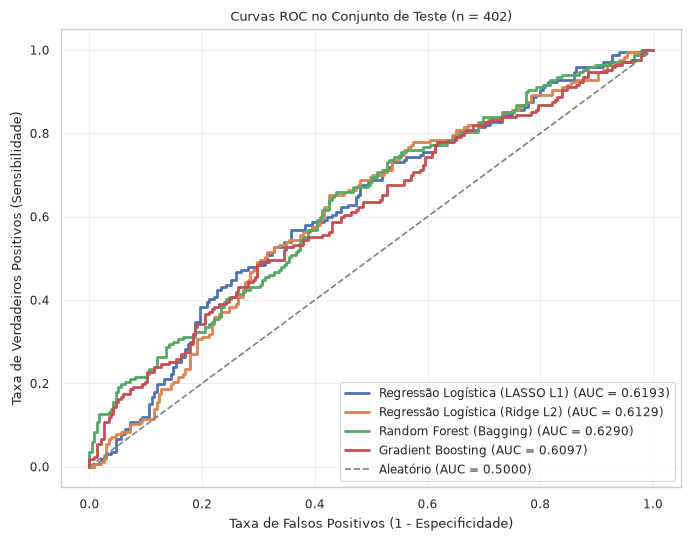

/home/luishcr/iic_projeto_final/heart-failure-outcome-prediction-fork1/results/figures/roc_curves_test.pdf

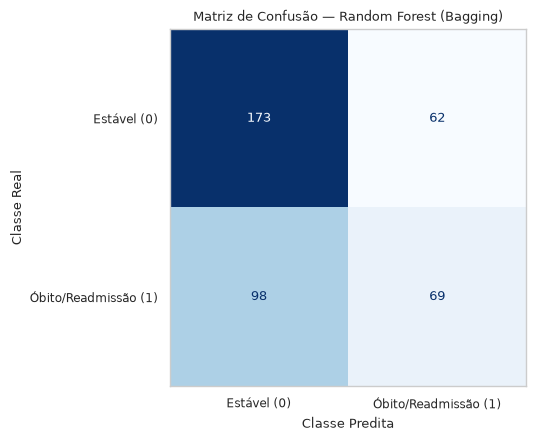

/home/luishcr/iic_projeto_final/heart-failure-outcome-prediction-fork1/results/figures/confusion_matrix_best.pdf

In [43]:
# 1. Tabela comparativa no conjunto de teste
test_summary = evaluate.evaluate_models_on_test(best_models, X_test, y_test)
print("--- Desempenho Final no Conjunto de Teste (n = 402) ---")
display(
    test_summary.style.hide(axis="index").format({
        "ROC-AUC": "{:.4f}",
        "Acurácia": "{:.4f}",
        "Precisão": "{:.4f}",
        "Sensibilidade (Recall)": "{:.4f}",
        "F1-Score": "{:.4f}",
    })
)

# 2. Curvas ROC sobrepostas
evaluate.plot_roc_curves(best_models, X_test, y_test)

# 3. Matriz de Confusão do modelo vencedor no teste
best_model_name = test_summary.iloc[0]["Modelo"]
evaluate.plot_confusion_matrix(best_models[best_model_name], best_model_name, X_test, y_test)

### 4.2 Interpretabilidade Clínica dos Atributos

Para identificar quais variáveis clínicas, fármacos e indicadores de ausência (*missing flags*) mais contribuem para a predição de óbito ou readmissão em 6 meses, analisamos a importância intrínseca de Gini no Random Forest e os coeficientes não-nulos (direção de risco em *log-odds*) da Regressão Logística LASSO ($\ell_1$).

LASSO (L1) manteve 72 de 234 atributos com coeficiente não-nulo.


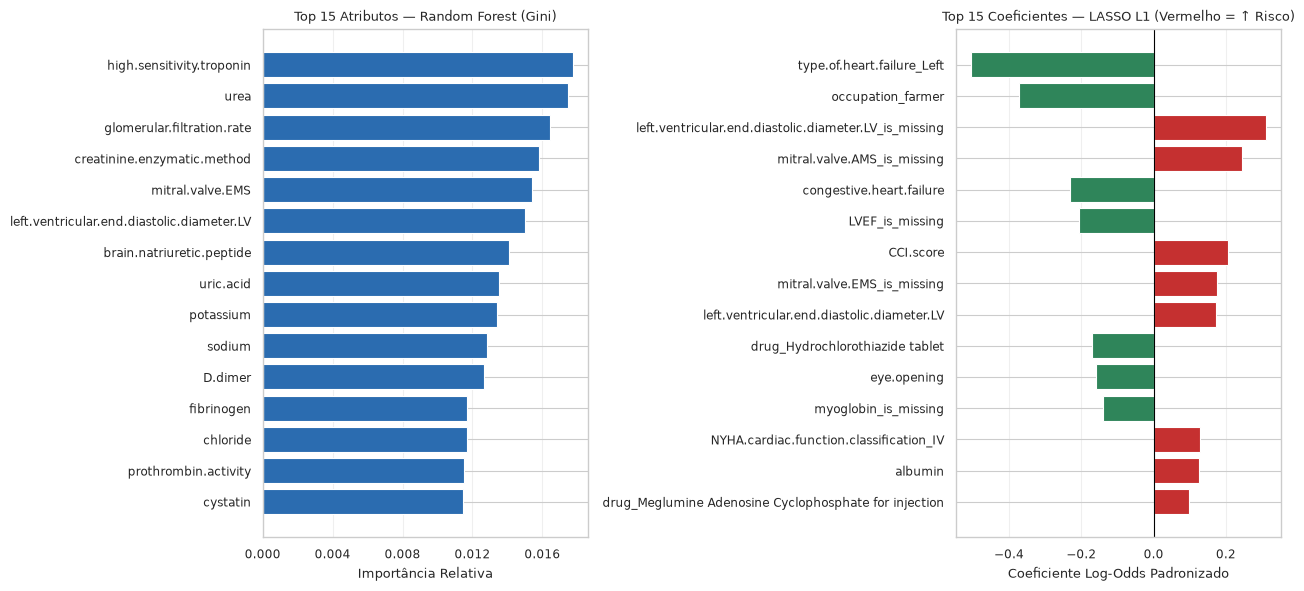

/home/luishcr/iic_projeto_final/heart-failure-outcome-prediction-fork1/results/figures/feature_importance.pdf.pdf

In [44]:
rf_top, lasso_top = evaluate.plot_clinical_interpretability(
    rf_pipeline=best_models["Random Forest (Bagging)"],
    lasso_pipeline=best_models["Regressão Logística (LASSO L1)"],
    top_n=15,
)